<h1><center>Сегментация изображений</h1></center>

Делиться обычно на семантическую, instance и паноптическую.

<h2>Семантическая сегменация

In [1]:
import torch
from torchvision.datasets import VOCSegmentation


dataset = VOCSegmentation(root='D:/MIREA/DPO/Learning/Practic2_8/SimpleNN', image_set='trainval', download=False)


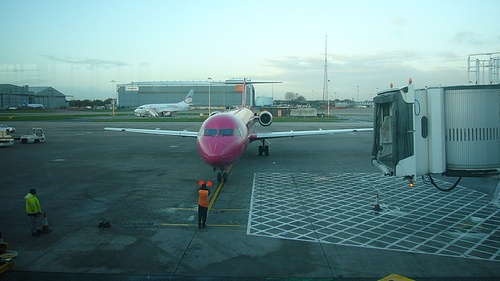

In [2]:
dataset[0][0]

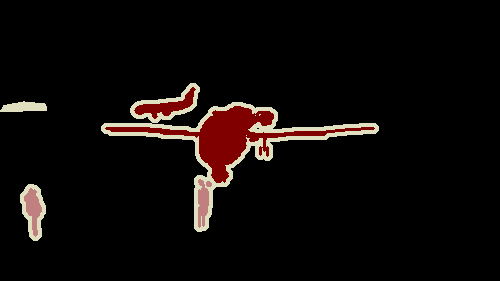

In [3]:
dataset[0][1]

In [27]:
import torchvision.transforms as T
import numpy as np


transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=[.485, .456, .406], std=[.229, .224, .225])
])

def get_segment_labels(image, model, device):
    image = transform(image).to(device)
    image = image.unsqueeze(0)
    outputs = model(image)
    return outputs

def decode_sigmap(outputs, num_classes=21):
    image = torch.argmax(outputs.squeeze(), dim=0).detach().cpu().numpy()
    label_columns = np.array([
        (0, 0, 0),
        (128, 0, 0),
        (0, 128, 0),
        (128, 128, 0),
        (0, 0, 128),
        (128, 0, 128),
        (0, 128, 128),
        (128, 128, 128),
        (64, 0, 0),
        (192, 0, 0),
        (64, 128, 0),
        (192, 128, 0),
        (64, 0, 128),
        (192, 0, 128),
        (64, 128, 128),
        (192, 128, 128),
        (0, 64, 0),
        (128, 64, 0),
        (0, 192, 0),
        (128, 192, 0),
        (0, 64, 128),
    ])
    r = np.zeros_like(image).astype(np.uint8)
    g = np.zeros_like(image).astype(np.uint8)
    b = np.zeros_like(image).astype(np.uint8)
    for label_num in range(0, num_classes):
        idx = image == label_num
        r[idx] = label_columns[label_num, 0]
        g[idx] = label_columns[label_num, 1]
        b[idx] = label_columns[label_num, 2]
    rgb = np.stack([r, g, b], axis=2)
    return rgb

In [16]:
import cv2


def image_overlay(image, segmented_image):
    alpha = .6
    beta = 1 - alpha
    gamma = 0

    image = np.array(image)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    cv2.addWeighted(segmented_image, alpha, image,  beta, gamma, image)
    return image

In [17]:
from torchvision.models.segmentation import fcn_resnet50


model = fcn_resnet50(weights="DEFAULT")
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
model.eval().to(device)
model

FCN(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequenti

In [18]:
import matplotlib.pyplot as plt


@torch.inference_mode()
def inference(image, model, device):
    outputs = get_segment_labels(image[0], model, device)
    outputs = outputs['out']
    segmented_image = decode_sigmap(outputs)
    final_image = image_overlay(image[0], segmented_image)
    plt.imshow(final_image)
    plt.title('Segmented image')
    plt.show()

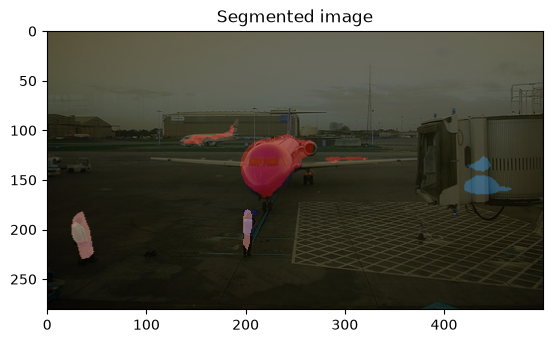

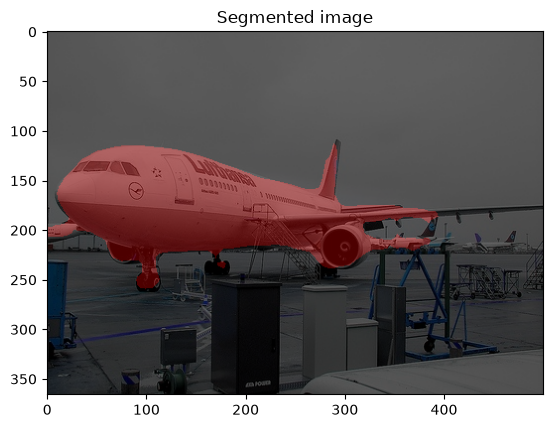

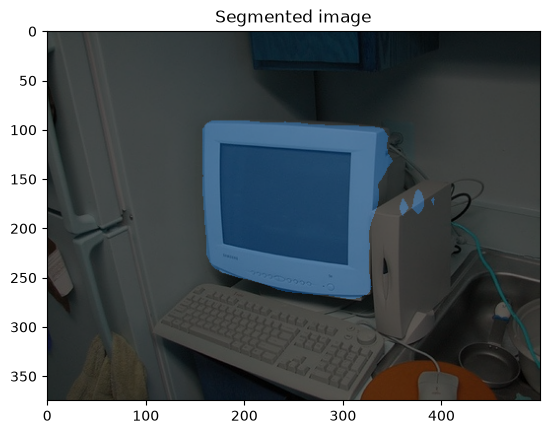

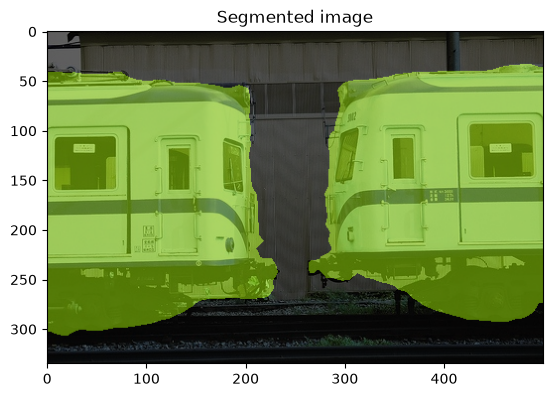

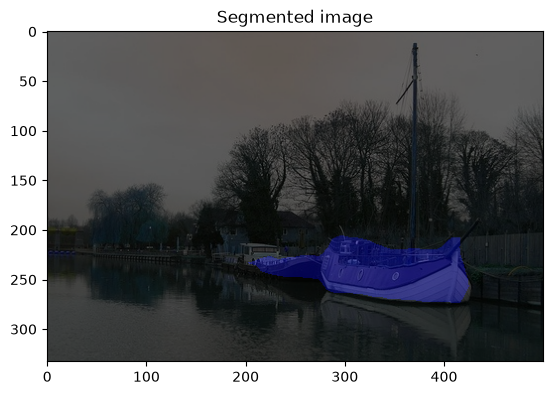

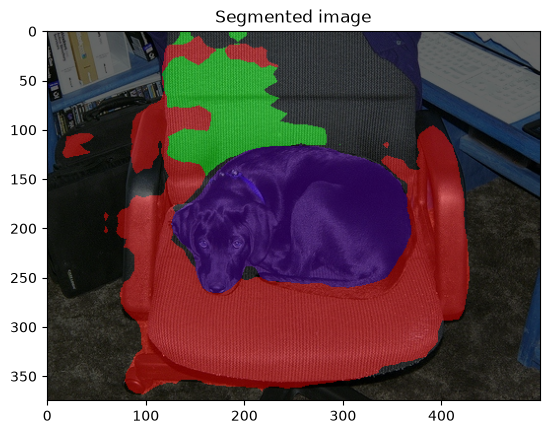

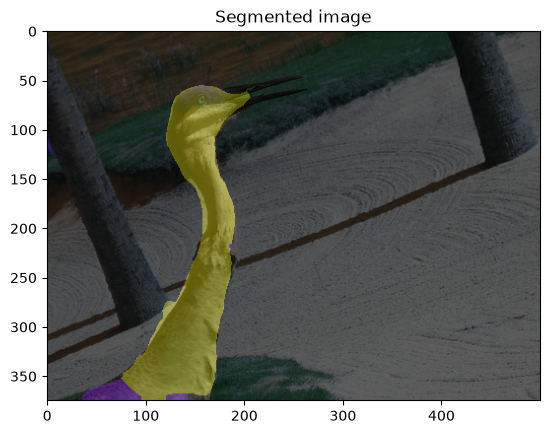

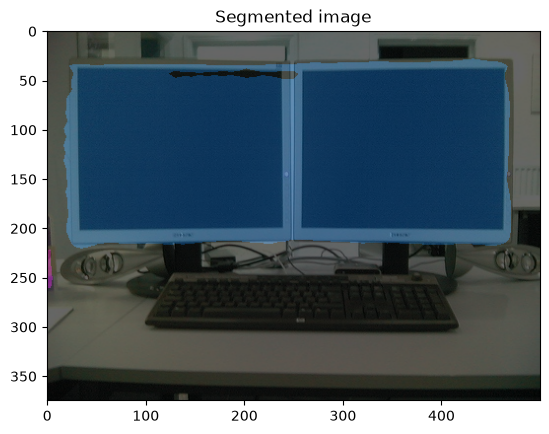

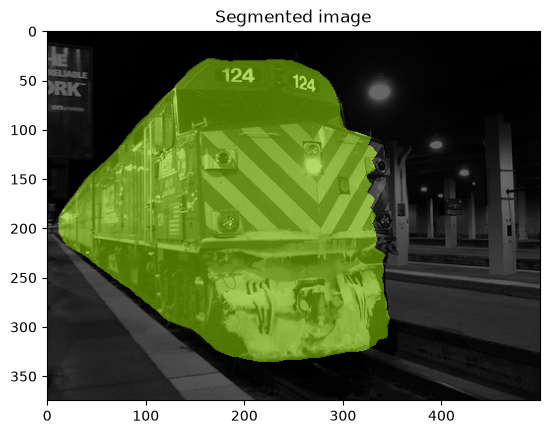

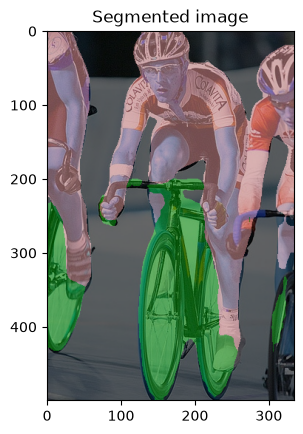

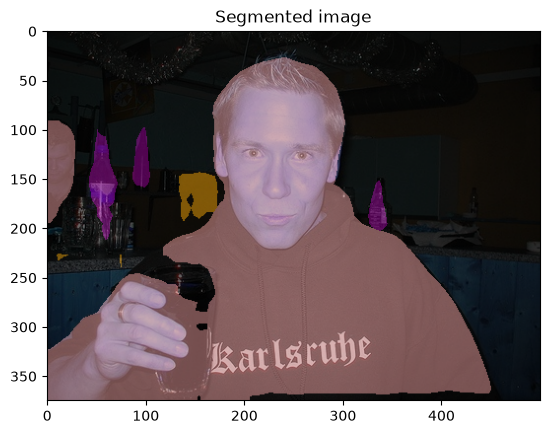

In [19]:
count = 0
for image in dataset:
    inference(image, model, device)
    count += 1
    if count > 10:
        break

<h2>Экземплярная сегментация


In [20]:
names = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella', 'N/A', 'N/A',
    'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'N/A', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl',
    'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
    'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table',
    'N/A', 'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone',
    'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A', 'book',
    'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]


In [21]:
COLOURS = np.random.uniform(0, 255, size=(len(names), 3))
COLOURS

array([[144.73209396, 224.33406917, 254.24020863],
       [205.07158526,  92.2136037 , 120.93912336],
       [124.93536436,  67.08776278, 237.23409407],
       [152.94777137,  66.04866091,  39.06148369],
       [150.45096497,  31.67058165, 104.72859547],
       [131.41284847, 187.65146418,  28.25144369],
       [152.8766675 , 147.52454357, 160.65179716],
       [219.81650352, 118.40157401, 184.60357148],
       [233.13872725, 115.28444618, 245.69924919],
       [106.49729492,  28.8953403 , 159.36352058],
       [225.67566708,  92.64179246, 105.84007261],
       [117.0970586 ,  49.53319667,   5.01697729],
       [189.07738207,  75.95401166, 159.41561836],
       [127.22838151,  80.34160067, 239.47960905],
       [240.76047375, 197.7224349 , 160.83991055],
       [168.03323395,  39.18097034,  85.13919628],
       [231.13861656, 170.15349175, 200.11916656],
       [217.95528731, 239.02695036,  17.43483621],
       [178.85987597, 120.84365661, 225.42054452],
       [ 34.51786401, 160.04206

In [45]:
def get_outputs(image, model, threshold):
    with torch.inference_mode():
        outputs = model(image)
    scores = list(outputs[0]['scores'].detach().cpu().numpy())
    threshed = [scores.index(i) for i in scores if i > threshold]
    threshed_count = len(threshed)
    masks = (outputs[0]['masks'] > .5).squeeze().detach().cpu().numpy()
    masks = masks[:threshed_count]
    boxes = [[(int(i[0]), int(i[1])), (int(i[2]), int(i[3]))] for i in outputs[0]['boxes'].detach().cpu()]
    boxes = boxes[:threshed_count]
    labels = [names[i] for i in outputs[0]['labels']]
    return masks, boxes, labels

In [69]:
import random

def decide_segmap_IS(image, masks, boxes, labels):
    alpha = 1
    beta = .6
    gamma = 0
    for i in range(len(masks)):
        r = np.zeros_like(masks[i]).astype(np.uint8)
        g = np.zeros_like(masks[i]).astype(np.uint8)
        b = np.zeros_like(masks[i]).astype(np.uint8)
        colour = COLOURS[random.randrange(0, len(COLOURS))]
        print(r.shape, g.shape, b.shape)
        r[masks[i] == 1], g[masks[i] == 1], b [masks[i] == 1] = colour
        segmap = np.stack([r, g, b], axis=2)
        image = np.array(image)
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        cv2.addWeighted(image, alpha, segmap, beta, gamma, image)
        cv2.rectangle(image, boxes[i][0], boxes[i][1], color=colour, thickness=2)
        cv2.putText(image, labels[i], (boxes[i][0][0], boxes[i][0][1] - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, colour,
                    thickness=2, lineType=cv2.LINE_AA)
    return image

In [63]:
transform_IS = T.Compose([
    T.ToTensor()
])

In [64]:
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2


model = maskrcnn_resnet50_fpn_v2(weights="DEFAULT", progress=True,
                                 num_classes=len(names))
model.eval().to(device)


MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         

In [65]:
@torch.inference_mode()
def inference_IS(image, model, device):
    orig_image = image[0].copy()
    image = transform_IS(image[0])
    image = image.unsqueeze(0).to(device)
    masks, boxes, labels = get_outputs(image, model, .5)
    final_image = decide_segmap_IS(orig_image, masks, boxes, labels)
    plt.imshow(final_image)
    plt.title('Segmented image')
    plt.show()

(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)
(281, 500) (281, 500) (281, 500)


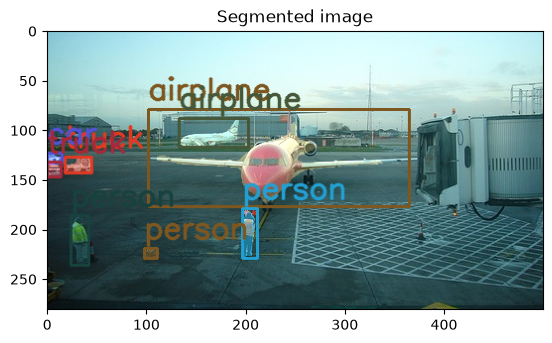

(366, 500) (366, 500) (366, 500)
(366, 500) (366, 500) (366, 500)
(366, 500) (366, 500) (366, 500)
(366, 500) (366, 500) (366, 500)
(366, 500) (366, 500) (366, 500)
(366, 500) (366, 500) (366, 500)


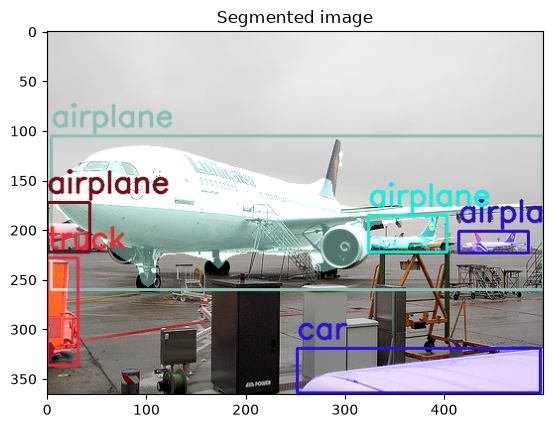

(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)
(375, 500) (375, 500) (375, 500)


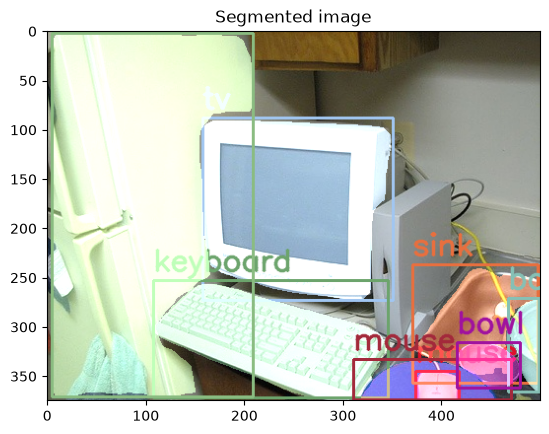

(335, 500) (335, 500) (335, 500)
(335, 500) (335, 500) (335, 500)


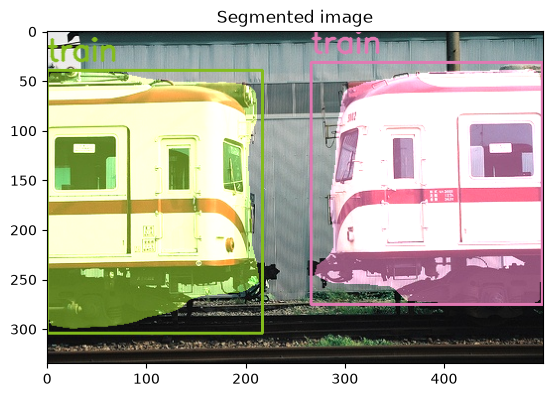

(333, 500) (333, 500) (333, 500)
(333, 500) (333, 500) (333, 500)
(333, 500) (333, 500) (333, 500)
(333, 500) (333, 500) (333, 500)
(333, 500) (333, 500) (333, 500)
(333, 500) (333, 500) (333, 500)


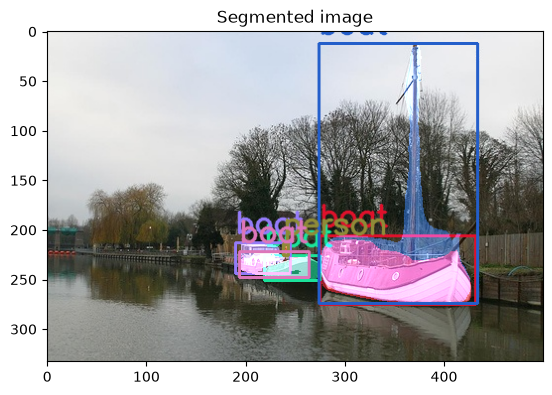

In [70]:
count = 0
for image in dataset:
    inference_IS(image, model, device)
    count += 1
    if (count >= 5):
        break

<h1><center>Практическое задание</h1></center>

1. Подобрать модель и с её помощью сделать паноптическую сегментацию на датасете VOCSegmentation